# `scripts/expected_score_slides.py`

報告 `report/expected_score.typ` 的投影片的統計圖：只讀前面各支的輸出表，不重估模型。

本 notebook 由 `notebooks/build.py` 從腳本自動產生，內容以腳本為準。

第一次分析報告（期望勝率的校準）投影片用的衍生數字與統計圖。
只讀 outputs/tables 的結果，不重估任何模型。推論把對局當成獨立，區間用 iid 標準誤。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

In [2]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTE, GRID = "#22262b", "#6b7178", "#e6e6e3"
CLASSES = ["Bullet", "Blitz", "Classical"]
COLOR = dict(zip(CLASSES, [BLUE, ORANGE, AQUA]))
MARK = dict(zip(CLASSES, ["o", "s", "^"]))
T = lambda f: pl.read_csv(f"outputs/tables/{f}.csv")
expit = lambda z: 1 / (1 + np.exp(-z))
elo = lambda d: 1 / (1 + 10 ** (-d / 400))

In [3]:
cox = T("calibration_cox")
# 老手對局（雙方 RD < 110）的 Elo 期望得分：分組殘差、截距與斜率、分層斜率
bc = T("expected_score_baselines_curve")
bcox = T("expected_score_baselines_cox").filter(pl.col("group") == "established")
allg = bcox.filter(pl.col("expected_score") == "elo")
st = T("expected_score_baselines_strata")

強方的校準後得分取 expit(beta logit E)，不含截距：截距是白方優勢，與哪一方較強無關

In [4]:
implied = pl.DataFrame([
    {"speed": r["speed"], "d": d, "elo": elo(d), "calibrated": expit(r["slope"] * np.log(elo(d) / (1 - elo(d)))),
     "beta": r["slope"]}
    for r in allg.iter_rows(named=True) for d in [200, 400]
])
print(implied)
implied.write_csv("outputs/tables/expected_score_slides_implied.csv")

shape: (6, 5)
┌───────────┬─────┬──────────┬────────────┬──────────┐
│ speed     ┆ d   ┆ elo      ┆ calibrated ┆ beta     │
│ ---       ┆ --- ┆ ---      ┆ ---        ┆ ---      │
│ str       ┆ i64 ┆ f64      ┆ f64        ┆ f64      │
╞═══════════╪═════╪══════════╪════════════╪══════════╡
│ Bullet    ┆ 200 ┆ 0.759747 ┆ 0.729787   ┆ 0.86298  │
│ Bullet    ┆ 400 ┆ 0.909091 ┆ 0.879434   ┆ 0.86298  │
│ Blitz     ┆ 200 ┆ 0.759747 ┆ 0.721875   ┆ 0.828446 │
│ Blitz     ┆ 400 ┆ 0.909091 ┆ 0.870746   ┆ 0.828446 │
│ Classical ┆ 200 ┆ 0.759747 ┆ 0.722461   ┆ 0.83098  │
│ Classical ┆ 400 ┆ 0.909091 ┆ 0.871401   ┆ 0.83098  │
└───────────┴─────┴──────────┴────────────┴──────────┘


半數帳號的對局前 RD 跌破 110 的局數；左截斷帳號的 RD 是設定值，排除

In [5]:
rd = T("novice_period_rd_by_games").filter(~pl.col("lt"))
cross = rd.filter(pl.col("prov_main") < 0.5).group_by("speed").agg(games=pl.col("k").min()).sort("speed")
print(cross)
cross.write_csv("outputs/tables/expected_score_slides_rd_cross.csv")

shape: (3, 2)
┌───────────┬───────┐
│ speed     ┆ games │
│ ---       ┆ ---   │
│ str       ┆ i64   │
╞═══════════╪═══════╡
│ Blitz     ┆ 13    │
│ Bullet    ┆ 14    │
│ Classical ┆ 13    │
└───────────┴───────┘


In [6]:
q = np.log(10) / 400

各分層的校準斜率

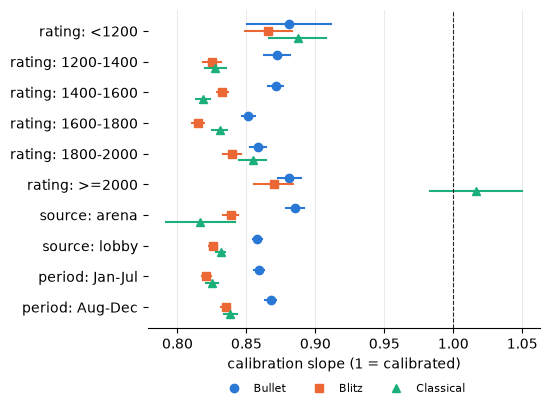

In [7]:
order = [("band", ["<1200", "1200-1400", "1400-1600", "1600-1800", "1800-2000", ">=2000"]), ("source", ["arena", "lobby"]), ("period", ["Jan-Jul", "Aug-Dec"])]
LABEL = {"band": "rating", "source": "source", "period": "period"}
rows = [(k, v) for k, vs in order for v in vs]
fig, ax = plt.subplots(figsize=(5.6, 4.2))
for j, tc in enumerate(CLASSES):
    c = st.filter(pl.col("speed") == tc)
    for i, (k, v) in enumerate(rows):
        r = c.filter(pl.col("stratum_type") == k, pl.col("stratum") == v).row(0, named=True)
        y = i + (j - 1) * 0.22
        ax.plot([r["slope"] - 1.96 * r["slope_se_iid"], r["slope"] + 1.96 * r["slope_se_iid"]], [y, y], color=COLOR[tc], lw=1.5)
        ax.plot(r["slope"], y, MARK[tc], color=COLOR[tc], ms=6, label=tc if i == 0 else None)
ax.axvline(1, color=INK, lw=0.8, ls="--")
ax.set_yticks(range(len(rows)), [f"{LABEL[k]}: {v}" for k, v in rows])
ax.invert_yaxis()
ax.set_xlabel("calibration slope (1 = calibrated)")
ax.grid(axis="x", color=GRID, lw=0.6)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
fig.tight_layout()
fig.savefig("outputs/figures/expected_score_slides_strata.svg")

In [8]:
dd = np.linspace(-650, 650, 300)

校準迴歸的配適值畫回得分的尺度：斜率小於 1 即比 Elo 的 sigmoid 平

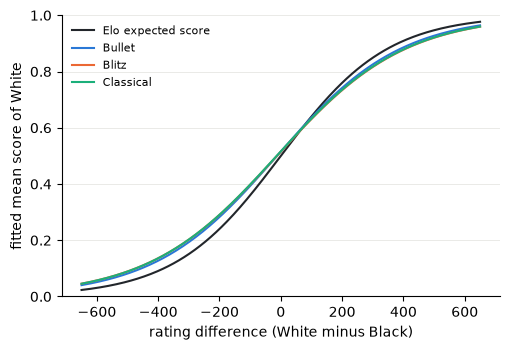

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.plot(dd, elo(dd), color=INK, lw=1.5, label="Elo expected score")
for tc in CLASSES:
    r = allg.filter(pl.col("speed") == tc).row(0, named=True)
    ax.plot(dd, expit(r["intercept"] + r["slope"] * q * dd), color=COLOR[tc], lw=1.5, label=tc)
ax.set_ylim(0, 1)
ax.set_xlabel("rating difference (White minus Black)")
ax.set_ylabel("fitted mean score of White")
ax.grid(axis="y", color=GRID, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig("outputs/figures/expected_score_slides_calfit.svg")

校準斜率依累計局數

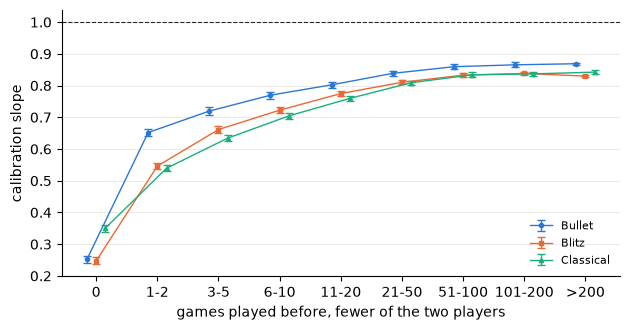

In [10]:
EXP = ["0", "1-2", "3-5", "6-10", "11-20", "21-50", "51-100", "101-200", ">200"]
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for j, tc in enumerate(CLASSES):
    c = cox.filter(pl.col("speed") == tc, pl.col("stratum_type") == "experience")
    r = [c.filter(pl.col("stratum") == v).row(0, named=True) for v in EXP]
    x = np.arange(len(EXP)) + (j - 1) * 0.15
    ax.errorbar(x, [q["slope"] for q in r], yerr=[[q["slope"] - q["slope_lo"] for q in r], [q["slope_hi"] - q["slope"] for q in r]], fmt=MARK[tc] + "-", color=COLOR[tc], ms=3, lw=1, capsize=3, label=tc)
ax.axhline(1, color=INK, lw=0.8, ls="--")
ax.set_xticks(range(len(EXP)), EXP)
ax.set_xlabel("games played before, fewer of the two players")
ax.set_ylabel("calibration slope")
ax.grid(axis="y", color=GRID, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("outputs/figures/expected_score_slides_experience.svg")

重放與表頭相符的比例，2014 年各月

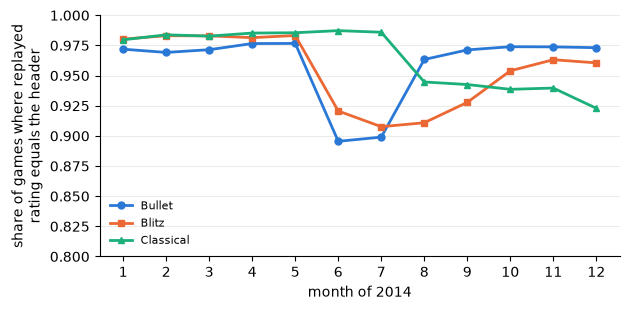

In [11]:
gm = T("glicko_replay_month").filter(pl.col("month").str.starts_with("2014"))
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for tc in CLASSES:
    c = gm.filter(pl.col("perf") == tc).sort("month")
    ax.plot(range(c.height), c["share_point"], MARK[tc] + "-", color=COLOR[tc], ms=5, lw=2, label=tc)
ax.set_xticks(range(12), [str(i) for i in range(1, 13)])
ax.set_xlabel("month of 2014")
ax.set_ylabel("share of games where replayed\nrating equals the header")
ax.set_ylim(0.8, 1)
ax.grid(axis="y", color=GRID, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig("outputs/figures/expected_score_slides_replay.svg")

RD 隨已下局數

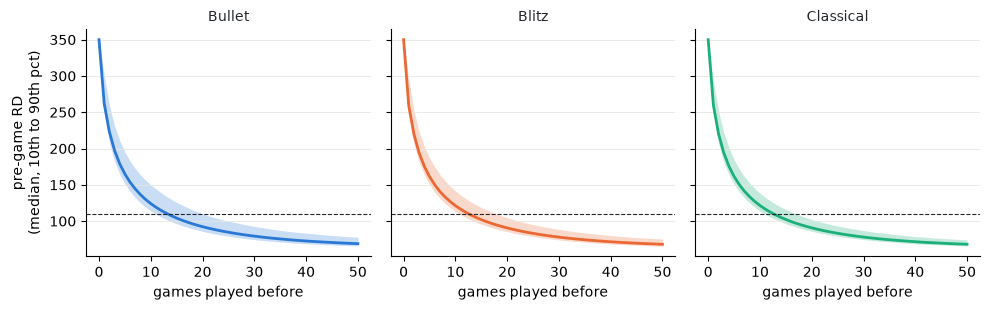

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, tc in zip(axes, CLASSES):
    c = rd.filter(pl.col("speed") == tc, pl.col("k") <= 50).sort("k")
    ax.fill_between(c["k"], c["rd_p10"], c["rd_p90"], color=COLOR[tc], alpha=0.25, lw=0)
    ax.plot(c["k"], c["rd_med"], color=COLOR[tc], lw=2)
    ax.axhline(110, color=INK, lw=0.8, ls="--")
    ax.set_title(tc, color=INK, fontsize=10)
    ax.set_xlabel("games played before")
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("pre-game RD\n(median, 10th to 90th pct)")
fig.tight_layout()
fig.savefig("outputs/figures/expected_score_slides_rd.svg")

校準斜率依雙方較大的 RD

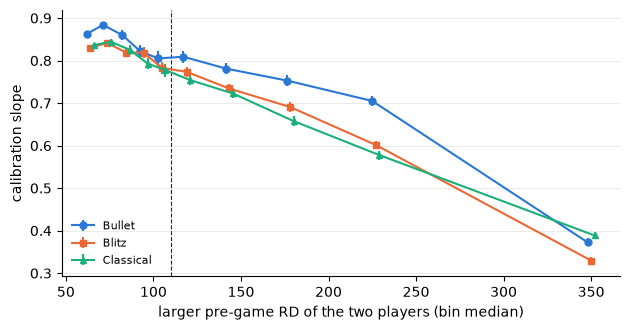

In [13]:
nc = T("novice_period_cox").filter(pl.col("stratum_type") == "rd_max")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for j, tc in enumerate(CLASSES):
    c = nc.filter(pl.col("speed") == tc).sort("rd_max_median")
    ax.errorbar(c["rd_max_median"] + (j - 1) * 2, c["slope"], yerr=1.96 * c["slope_se_iid"], fmt=MARK[tc] + "-", color=COLOR[tc], ms=5, lw=1.5, capsize=0, label=tc)
ax.axvline(110, color=INK, lw=0.8, ls="--")
ax.set_xlabel("larger pre-game RD of the two players (bin median)")
ax.set_ylabel("calibration slope")
ax.grid(axis="y", color=GRID, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig("outputs/figures/expected_score_slides_rdslope.svg")

老手對局的殘差，Elo 與 Glicko 的期望得分並排；圖例附各自的斜率

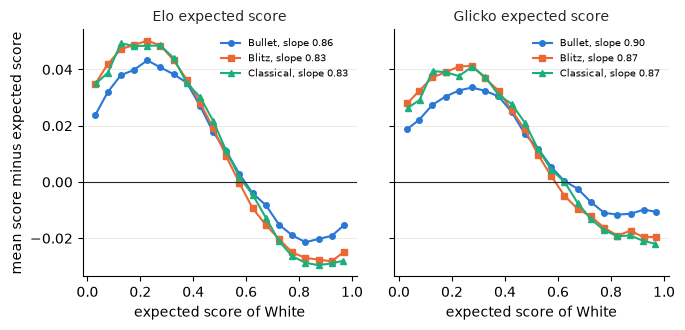

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4), sharey=True)
for ax, (m, title) in zip(axes, [("elo", "Elo expected score"), ("glicko", "Glicko expected score")]):
    for tc in CLASSES:
        c = bc.filter(pl.col("speed") == tc, pl.col("expected_score") == m).sort("e_bin")
        slope = bcox.filter(pl.col("speed") == tc, pl.col("expected_score") == m)["slope"][0]
        ax.plot(c["e_mean"], c["resid_mean"], MARK[tc], color=COLOR[tc], ms=4, ls="-", lw=1.5, label=f"{tc}, slope {slope:.2f}")
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_title(title, color=INK, fontsize=10)
    ax.set_xlabel("expected score of White")
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=7, loc="upper right")
axes[0].set_ylabel("mean score minus expected score")
fig.tight_layout()
fig.savefig("outputs/figures/expected_score_slides_elo_vs_glicko.svg")

配對隨機：2014 年各類批的實際批內相關與重新配對的 95% 區間

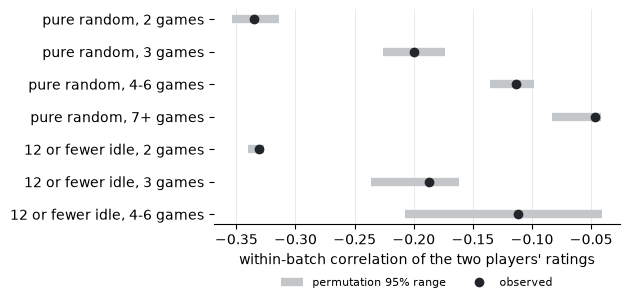

In [15]:
pm = T("arena_random_pairing_permutation").filter(pl.col("group").str.starts_with("2014|"), pl.col("group").str.count_matches(r"\|") == 2)
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for i, r in enumerate(pm.iter_rows(named=True)):
    ax.plot([r["corr_null_lo"], r["corr_null_hi"]], [i, i], color="#c4c7ca", lw=6, solid_capstyle="butt", label="permutation 95% range" if i == 0 else None)
    ax.plot(r["corr"], i, "o", color=INK, ms=6, label="observed" if i == 0 else None)
lab = {"random": "pure random", "smart": "12 or fewer idle"}
ax.set_yticks(range(pm.height), [f"{lab[g.split('|')[1]]}, {g.split('|')[2]} games" for g in pm["group"]])
ax.invert_yaxis()
ax.set_xlabel("within-batch correlation of the two players' ratings")
ax.grid(axis="x", color=GRID, lw=0.6)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.tight_layout()
fig.savefig("outputs/figures/expected_score_slides_pairing.svg")

選出的模型在 7-12 月的校準，淡色虛線為 Elo：得分殘差、和局機率、依累計局數的 Cox 斜率

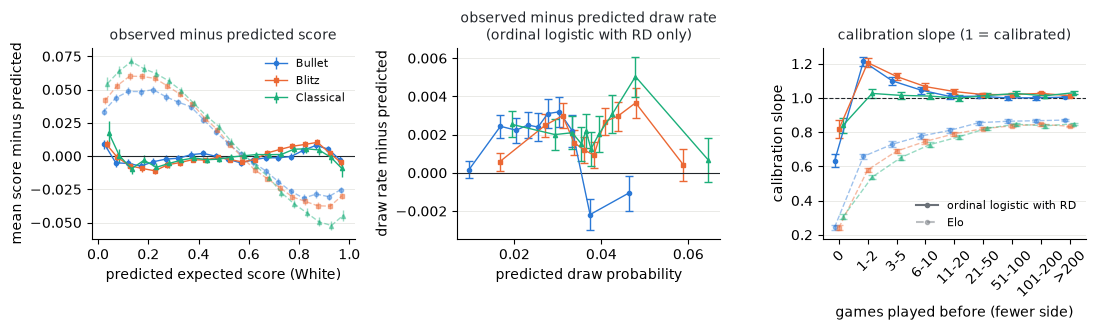

In [16]:
hc = T("expected_score_baselines_holdout_curve")
hx = T("expected_score_baselines_holdout_cox")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for j, tc in enumerate(CLASSES):
    for nm, style in [("elo", dict(ls="--", alpha=0.45)), ("rd_ordinal", dict(ls="-"))]:
        c = hc.filter(pl.col("speed") == tc, pl.col("model") == nm, pl.col("kind") == "score").sort("bin")
        axes[0].errorbar(c["pred_mean"] + (j - 1) * 0.006, c["resid_mean"], yerr=1.96 * c["resid_se_iid"], fmt=MARK[tc], color=COLOR[tc], ms=3, lw=1, capsize=0, **style, label=tc if nm == "rd_ordinal" else None)
        c = hx.filter(pl.col("speed") == tc, pl.col("model") == nm)
        r = [c.filter(pl.col("exp_bin") == v).row(0, named=True) for v in EXP]
        x = np.arange(len(EXP)) + (j - 1) * 0.15
        axes[2].errorbar(x, [q["slope"] for q in r], yerr=[[q["slope"] - q["slope_lo"] for q in r], [q["slope_hi"] - q["slope"] for q in r]], fmt=MARK[tc], color=COLOR[tc], ms=3, lw=1, capsize=3, **style)
    # 和局的 20 分位兩兩合併成 10 分位，三種速度疊在窄範圍內才看得清；合併的標準誤含組間差
    c = (
        hc.filter(pl.col("speed") == tc, pl.col("kind") == "draw")
        .with_columns(g=pl.col("bin") // 2, ss=(pl.col("n") - 1) * pl.col("n") * pl.col("resid_se_iid") ** 2)
        .group_by("g")
        .agg(
            pred_mean=(pl.col("pred_mean") * pl.col("n")).sum() / pl.col("n").sum(),
            resid_mean=(pl.col("resid_mean") * pl.col("n")).sum() / pl.col("n").sum(),
            ss=pl.col("ss").sum() + (pl.col("n") * (pl.col("resid_mean") - (pl.col("resid_mean") * pl.col("n")).sum() / pl.col("n").sum()) ** 2).sum(),
            n=pl.col("n").sum(),
        )
        .with_columns(se=(pl.col("ss") / (pl.col("n") - 1) / pl.col("n")).sqrt())
        .sort("g")
    )
    axes[1].errorbar(c["pred_mean"], c["resid_mean"], yerr=1.96 * c["se"], fmt=MARK[tc] + "-", color=COLOR[tc], ms=3, lw=1, capsize=3)
axes[0].axhline(0, color=INK, lw=0.8)
axes[0].set_xlabel("predicted expected score (White)")
axes[0].set_ylabel("mean score minus predicted")
axes[0].set_title("observed minus predicted score", color=INK, fontsize=10)
axes[1].set_title("observed minus predicted draw rate\n(ordinal logistic with RD only)", color=INK, fontsize=10)
axes[2].set_title("calibration slope (1 = calibrated)", color=INK, fontsize=10)
# 速度以顏色、模型以線型區分，兩組圖例分開放
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
axes[2].legend(handles=[
    plt.Line2D([], [], color=MUTE, ls="-", marker="o", ms=3, label="ordinal logistic with RD"),
    plt.Line2D([], [], color=MUTE, ls="--", marker="o", ms=3, alpha=0.45, label="Elo"),
], frameon=False, fontsize=8, loc="lower right")
axes[1].axhline(0, color=INK, lw=0.8)
axes[1].set_xlabel("predicted draw probability")
axes[1].set_ylabel("draw rate minus predicted")
axes[2].axhline(1, color=INK, lw=0.8, ls="--")
axes[2].set_xticks(range(len(EXP)), EXP, rotation=45)
axes[2].set_xlabel("games played before (fewer side)")
axes[2].set_ylabel("calibration slope")
for ax in axes:
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/figures/expected_score_slides_holdout.svg")

附錄：切點的兩個成分依平均等級分分組各自估計，對照線性與二次；區間同本次報告用 iid 標準誤

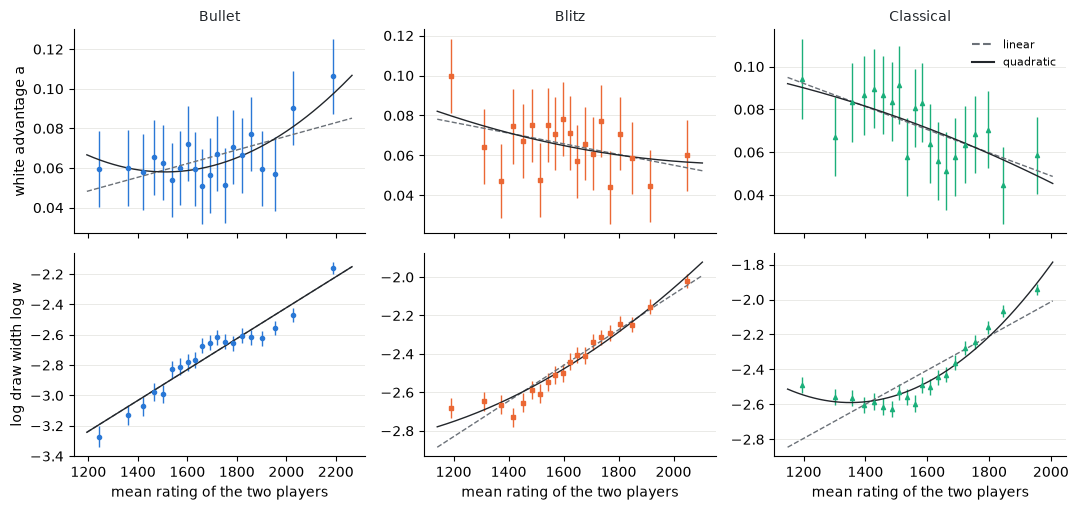

In [17]:
tb = T("threshold_rating_form_bins")
tv = T("threshold_rating_form_curve")
fig, axes = plt.subplots(2, 3, figsize=(11, 5.2), sharex="col")
for i, (part, lab) in enumerate([("a", "white advantage a"), ("log_w", "log draw width log w")]):
    for j, tc in enumerate(CLASSES):
        ax = axes[i, j]
        b = tb.filter(pl.col("speed") == tc, pl.col("part") == part)
        ax.errorbar(b["rbar"], b["est"], yerr=1.96 * b["se_iid"], fmt=MARK[tc], color=COLOR[tc], ms=3, lw=1, capsize=0)
        for nm, ls in [("linear", "--"), ("quad", "-")]:
            c = tv.filter(pl.col("speed") == tc, pl.col("part") == part, pl.col("model") == nm)
            ax.plot(c["rbar"], c["est"], ls, color=INK if nm == "quad" else MUTE, lw=1)
        if i == 0:
            ax.set_title(tc, color=INK, fontsize=10)
        else:
            ax.set_xlabel("mean rating of the two players")
        if j == 0:
            ax.set_ylabel(lab)
        ax.grid(axis="y", color=GRID, lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)
axes[0, 2].legend(handles=[
    plt.Line2D([], [], color=MUTE, ls="--", label="linear"),
    plt.Line2D([], [], color=INK, ls="-", label="quadratic"),
], frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig("outputs/figures/expected_score_slides_threshold.svg")